# Talos - Room Temperature Forecast

In this notebook we try to predict the room temperature **10 minutes from now** using the data from our Talos logger.

We use a Random Forest Regressor, then compare it with a simple baseline and with the R3 rule we made in Assignment 2.

Run `00_preprocessing.ipynb` first, it makes `data_1min.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Load the per-minute data

In [2]:
m = pd.read_csv('data_1min.csv', parse_dates=['pc_time'], index_col='pc_time')
print(m.shape)
m.head()

(7411, 12)


,temp_c,humidity_pct,mic_peak,mic_median_5m,occupied,ac_on,setpoint,hour,weekday,temp_change_5m,temp_30m_ago,ac_setting
pc_time,,,,,,,,,,,,
2026-11-05 20:29:00,26.300,76.350,294231.5,386574.5,1,1,16.0,20,3,NaN,NaN,16C
2026-11-05 20:30:00,26.150,75.027,355310.5,394682.0,1,1,16.0,20,3,NaN,NaN,16C
2026-11-05 20:31:00,25.977,74.177,260611.5,358381.5,1,1,16.0,20,3,NaN,NaN,16C
2026-11-05 20:32:00,25.850,73.890,128911.0,303576.5,1,1,16.0,20,3,NaN,NaN,16C
2026-11-05 20:33:00,25.753,73.097,121071.0,237622.5,1,1,16.0,20,3,NaN,NaN,16C


## 2. Features and target

Target = temperature 10 minutes later.

Features = things Talos already knows at that moment (temp, how fast it's changing, humidity, mic, AC state, hour).

In [3]:
HORIZON = 10  # how many minutes ahead we want to predict

m['target'] = m['temp_c'].shift(-HORIZON)

# skip rows where there is a gap in the log (laptop off etc), otherwise the target is wrong
gap_ok = (m.index.to_series().shift(-HORIZON) - m.index.to_series()) == pd.Timedelta(minutes=HORIZON)
data = m[gap_ok].dropna()

FEATURES = ['temp_c', 'temp_change_5m', 'humidity_pct', 'mic_peak', 'ac_on', 'setpoint', 'hour']
X = data[FEATURES]
y = data['target']
print(len(data), 'rows')

7371 rows


## 3. Train / test split

Since this is time series data we don't shuffle. First 80% is for training, the last 20% (the last day) is for testing.

In [4]:
split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print('train:', X_train.index.min(), 'to', X_train.index.max())
print('test :', X_test.index.min(), 'to', X_test.index.max())

train: 2026-11-05 20:59:00 to 2026-11-09 23:14:00
test : 2026-11-09 23:15:00 to 2026-11-10 23:49:00


## 4. Train the model

We keep the settings simple: 100 trees, max depth 10.

In [5]:
model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

## 5. Evaluate

For the baseline we just say the temperature in 10 minutes = the temperature now. If the model can't beat this, it's not useful.

In [6]:
def scores(name, y_true, y_pred):
    return {
        'model': name,
        'MAE (°C)': round(mean_absolute_error(y_true, y_pred), 3),
        'RMSE (°C)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 3),
        'R2': round(r2_score(y_true, y_pred), 3),
    }

results = pd.DataFrame([
    scores('Baseline (no change)', y_test, X_test['temp_c']),
    scores('Random Forest', y_test, pred),
])
results

,model,MAE (°C),RMSE (°C),R2
0,Baseline (no change),0.186,0.271,0.992
1,Random Forest,0.162,0.223,0.995


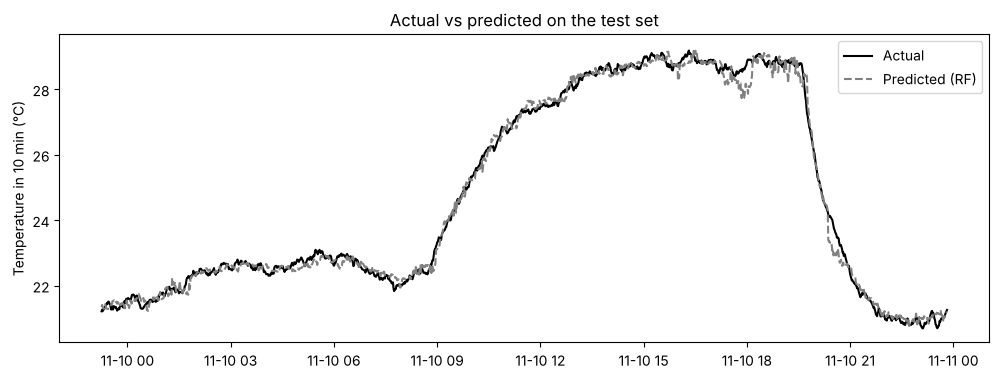

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(y_test.index, y_test.values, label='Actual', color='black')
plt.plot(y_test.index, pred, label='Predicted (RF)', color='gray', linestyle='--')
plt.ylabel('Temperature in 10 min (°C)')
plt.title('Actual vs predicted on the test set')
plt.legend()
plt.show()

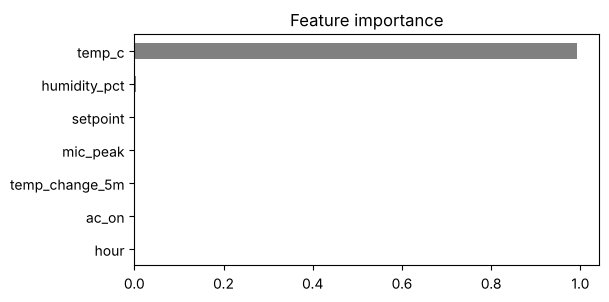

In [8]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind='barh', color='gray', figsize=(6, 3), title='Feature importance')
plt.show()

## 6. Compare with our rule from Assignment 2 (R3)

In Assignment 2, R3 used a fixed formula to guess the room temperature: `20.9 + 0.32 x (setpoint - 16)`. Here we compare that formula with our model. We only use rows where the AC has been on at the same setpoint for at least 60 minutes, because that's when the formula is supposed to work.

In [9]:
test = data.iloc[split:].copy()
test['pred_rf'] = pred
same_sp = test['setpoint'].groupby((test['setpoint'] != test['setpoint'].shift()).cumsum()).cumcount()
settled = test[(test['ac_on'] == 1) & (same_sp >= 60)].copy()
settled['pred_rule'] = 20.9 + 0.32 * (settled['setpoint'] - 16)

pd.DataFrame([
    scores('Rule R3 formula', settled['target'], settled['pred_rule']),
    scores('Random Forest', settled['target'], settled['pred_rf']),
]).assign(rows=len(settled))

,model,MAE (°C),RMSE (°C),R2,rows
0,Rule R3 formula,0.285,0.473,0.54,610
1,Random Forest,0.133,0.171,0.94,610


## 7. Save the model

So we can load it later without training again.

In [10]:
joblib.dump({'model': model, 'features': FEATURES, 'horizon_min': HORIZON}, 'temp_forecast_model.pkl')
print('saved temp_forecast_model.pkl')

saved temp_forecast_model.pkl


## 8. Try it with one reading

In [11]:
now = pd.DataFrame([{
    'temp_c': 26.5, 'temp_change_5m': -0.4, 'humidity_pct': 70,
    'mic_peak': 45000, 'ac_on': 1, 'setpoint': 16, 'hour': 21,
}])
print('Predicted temperature in 10 min:', round(model.predict(now[FEATURES])[0], 2), '°C')

Predicted temperature in 10 min: 25.91 °C


## How we're going to use this in Talos (real time)

**Purpose:** know where the room temperature is going, so the AC can act early instead of waiting.

**How it runs:**
1. The ESP32 already sends every row over MQTT to our Go server (`talos/readings`).
2. A small Python script on the same laptop subscribes to that topic, keeps the last 30 minutes in memory, and once per minute builds the same features as in this notebook.
3. It loads `temp_forecast_model.pkl` and predicts the temperature in 10 minutes.
4. The result is sent to ThingsBoard as `predicted_temp_10m`, so the dashboard shows the prediction next to the real value and keeps a history of it.
5. It's also sent back to the board (for example on `talos/ml`). The automation uses it to:
   - raise the setpoint at night when the predicted temperature is already low enough (better than the fixed R3 formula)
   - turn the AC on a bit earlier if the room is predicted to go above 26 °C

If the script or the laptop is off, the board just falls back to the normal R1 to R5 rules.